# Etapa 7 — Gráficos finais e tabela-resumo

Nada é reestimado aqui: o notebook só **lê os arquivos salvos** pelas etapas 4 a 6 e monta
os gráficos finais (PNG em `resultados/figuras/`) e a tabela-resumo (`resultados/resumo.xlsx`).

Convenção de cores em **todos** os gráficos: **azul = externo**, **laranja = doméstico**,
**cinza = não explicado**.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

RES = Path("resultados")
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Cores (paleta validada para daltonismo) e tinta de texto
AZUL, LARANJA = "#2a78d6", "#eb6834"
CINZA_CLARO, CINZA_MEDIO = "#e1e0d9", "#a3a29b"
TINTA, TINTA_2, MUDO = "#0b0b0b", "#52514e", "#898781"
FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUDO, "ytick.color": MUDO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "legend.frameon": False, "legend.labelcolor": TINTA_2,
})

def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png", dpi=200, bbox_inches="tight")
    plt.show()

def eixo_anos(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

def marcar_minimo(ax, serie, cor=TINTA):
    """Ponto e rótulo no mínimo da série."""
    data, valor = serie.idxmin(), serie.min()
    ax.plot(data, valor, "o", ms=7, color=AZUL, mec=FUNDO, mew=2, zorder=5)
    ax.annotate(f"mínimo: {valor:.0%} ({MESES[data.month - 1]}/{data.year})", (data, valor),
                xytext=(-10, -14), textcoords="offset points", ha="right", va="top",
                fontsize=9, color=cor, zorder=6,
                bbox=dict(boxstyle="round,pad=0.2", fc=FUNDO, ec="none"))   # fundo esconde linhas atrás

In [2]:
# Resultados das etapas anteriores
decomp_r2 = pd.read_csv(RES / "etapa5_decomposicao_r2.csv", index_col=0)        # etapas 4 e 5
coef = pd.read_csv(RES / "etapa5_coeficientes_limpo.csv", index_col=0)           # etapa 5
reg60 = pd.read_csv(RES / "etapa6_regressao_janela60.csv", index_col=0, parse_dates=True)
reg84 = pd.read_csv(RES / "etapa6_regressao_janela84.csv", index_col=0, parse_dates=True)

variacoes = pd.read_csv("dados/tratados/variacoes_mensais.csv", index_col=0, parse_dates=True)
limpas = pd.read_csv("dados/tratados/domesticas_limpas.csv", index_col=0, parse_dates=True)

serie60 = reg60["externo / explicado"]

## Painel A — amostra completa

Cada linha divide **100% da variância mensal do câmbio**.

In [3]:
e4, e5 = decomp_r2["Etapa 4 (CDS original)"], decomp_r2["Etapa 5 (domésticas limpas)"]

painel_a = pd.DataFrame({
    "Regressão ingênua (etapa 4)": {"externo": e4["só externo"], "sobreposição": e4["sobreposição"],
                                    "doméstico": e4["só doméstico"], "não explicado": 1 - e4["total"]},
    "Regressão limpa (etapa 5)":   {"externo": e5["só externo"], "sobreposição": 0.0,
                                    "doméstico": e5["só doméstico"], "não explicado": 1 - e5["total"]},
}).T
painel_a["externo / explicado"] = painel_a["externo"] / (painel_a["externo"] + painel_a["doméstico"])
painel_a.loc["Regressão ingênua (etapa 4)", "externo / explicado"] = float("nan")   # há sobreposição sem dono
painel_a.round(3)

,externo,sobreposição,doméstico,não explicado,externo / explicado
Regressão ingênua (etapa 4),0.09,0.35,0.17,0.39,NaN
Regressão limpa (etapa 5),0.44,0.00,0.17,0.39,0.721


## Gráfico 1 — A limpeza do risco-país dá dono à sobreposição

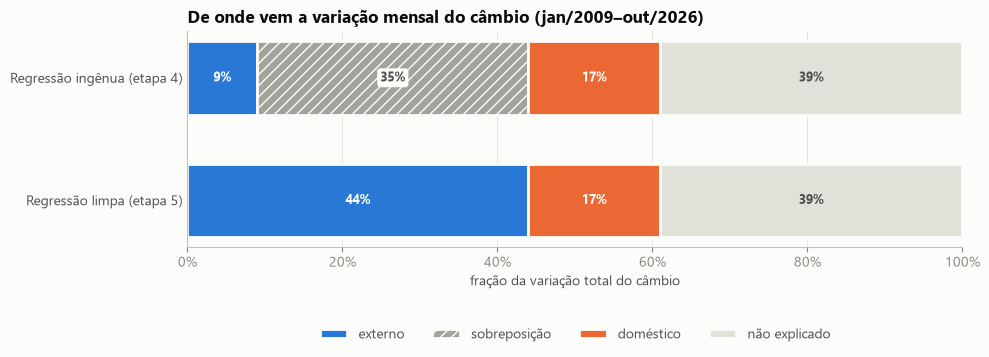

In [4]:
segmentos = [("externo", AZUL, None), ("sobreposição", CINZA_MEDIO, "///"),
             ("doméstico", LARANJA, None), ("não explicado", CINZA_CLARO, None)]
ordem = painel_a.index[::-1]   # etapa 4 no topo

fig, ax = plt.subplots(figsize=(10, 2.8))
esquerda = pd.Series(0.0, index=ordem)
for nome, cor, hachura in segmentos:
    largura = painel_a.loc[ordem, nome]
    ax.barh(ordem, largura, left=esquerda, height=0.6, color=cor, hatch=hachura,
            edgecolor=FUNDO, linewidth=2, label=nome)
    for metodo in ordem:   # rótulo só em segmentos largos o bastante
        if largura[metodo] >= 0.06:
            cor_txt = "white" if nome in ("externo", "doméstico") else TINTA_2
            caixa = dict(boxstyle="round,pad=0.25", fc=FUNDO, ec="none") if hachura else None
            ax.text(esquerda[metodo] + largura[metodo] / 2, metodo, f"{largura[metodo]:.0%}",
                    ha="center", va="center", fontsize=9, color=cor_txt, fontweight="bold", bbox=caixa)
    esquerda += largura

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=TINTA_2, length=0)
ax.set_title("De onde vem a variação mensal do câmbio (jan/2009–out/2026)")
ax.set_xlabel("fração da variação total do câmbio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4)
salvar(fig, "1_comparacao_metodos")

## Gráfico 2 — Efeito de cada variável (regressão limpa)

Coeficientes padronizados do modelo completo limpo, com intervalo de 95% (erros HAC).
Leitura: um choque de 1 desvio-padrão na variável move o câmbio em *β* desvios-padrão.
Para as externas é o efeito **total** (inclusive o que passa pelo risco-país); para as
domésticas, só a parte **não explicada** pelo cenário externo.

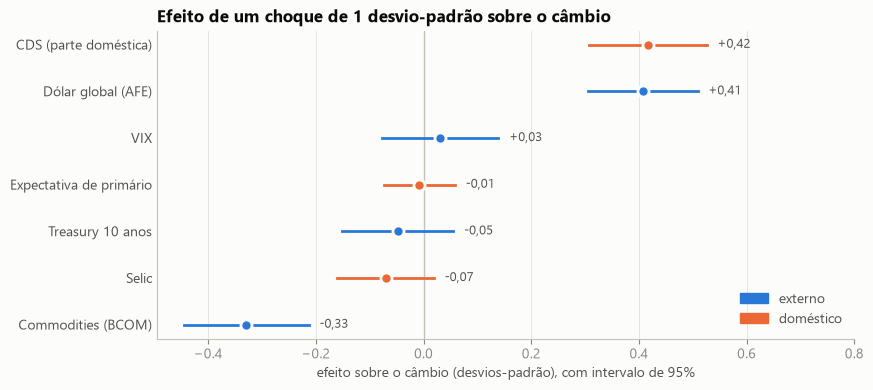

In [5]:
nomes = {
    "d_ust10": "Treasury 10 anos", "dl_vix": "VIX", "dl_dolar": "Dólar global (AFE)", "dl_commod": "Commodities (BCOM)",
    "d_selic_dom": "Selic", "d_primario_dom": "Expectativa de primário", "dl_cds_dom": "CDS (parte doméstica)",
}
cor_bloco = {v: (AZUL if v in ("d_ust10", "dl_vix", "dl_dolar", "dl_commod") else LARANJA) for v in nomes}

c = coef.sort_values("coef")
ic = 1.96 * c["erro_padrao_hac"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvline(0, color="#c3c2b7", lw=1)
for i, v in enumerate(c.index):
    ax.plot([c.loc[v, "coef"] - ic[v], c.loc[v, "coef"] + ic[v]], [i, i], color=cor_bloco[v], lw=2)
    ax.plot(c.loc[v, "coef"], i, "o", ms=8, color=cor_bloco[v], mec=FUNDO, mew=2)
    ax.text(c.loc[v, "coef"] + ic[v] + 0.02, i, f"{c.loc[v, 'coef']:+.2f}".replace(".", ","),
            va="center", fontsize=9, color=TINTA_2)
ax.set_yticks(range(len(c)), [nomes[v] for v in c.index])
ax.tick_params(axis="y", colors=TINTA_2, length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(min(-0.35, (c["coef"] - ic).min() - 0.05), max(0.8, (c["coef"] + ic).max() + 0.15))
ax.set_xlabel("efeito sobre o câmbio (desvios-padrão), com intervalo de 95%")
ax.set_title("Efeito de um choque de 1 desvio-padrão sobre o câmbio")
ax.legend(handles=[Patch(color=AZUL, label="externo"), Patch(color=LARANJA, label="doméstico")],
          loc="lower right")
salvar(fig, "2_efeito_por_variavel")

## Gráfico 3 — Peso externo ao longo do tempo (versão técnica)

Cada ponto = **fim** de uma janela. Linhas cinzas sólidas = episódio **entra** na janela de 60 meses;
pontilhadas = episódio **sai** dela (60 meses depois).

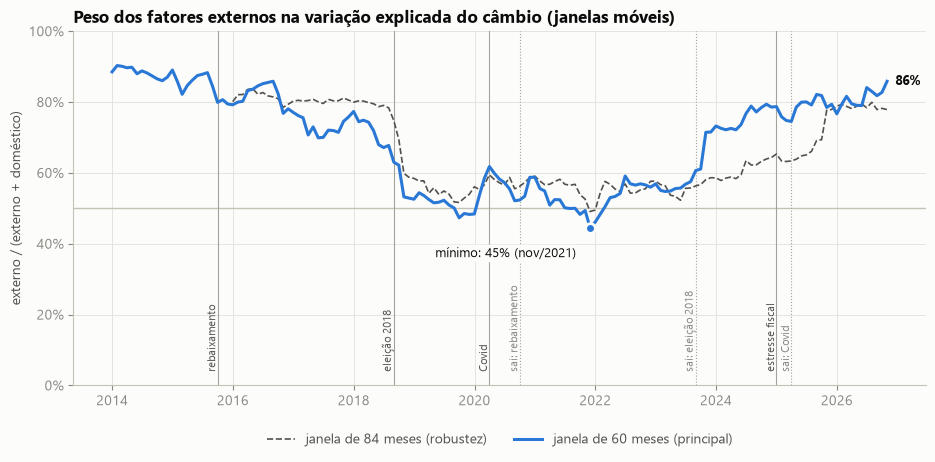

In [6]:
episodios = {"2015-09-30": "rebaixamento", "2018-08-31": "eleição 2018",
             "2020-03-31": "Covid", "2024-12-31": "estresse fiscal"}

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axhline(0.5, color="#c3c2b7", lw=1)
for data, nome in episodios.items():
    entra = pd.Timestamp(data)
    sai = entra + pd.DateOffset(months=60)
    ax.axvline(entra, color=CINZA_MEDIO, lw=0.8)
    ax.text(entra, 0.03, f" {nome}", rotation=90, fontsize=8, color=TINTA_2, va="bottom", ha="right")
    if sai <= serie60.index[-1]:
        ax.axvline(sai, color=CINZA_MEDIO, lw=0.8, ls=":")
        ax.text(sai, 0.03, f" sai: {nome}", rotation=90, fontsize=8, color=MUDO, va="bottom", ha="right")

ax.plot(reg84.index, reg84["externo / explicado"], color=TINTA_2, lw=1.2, ls="--", label="janela de 84 meses (robustez)")
ax.plot(serie60.index, serie60, color=AZUL, lw=2.2, label="janela de 60 meses (principal)")
marcar_minimo(ax, serie60)
ax.annotate(f"{serie60.iloc[-1]:.0%}", (serie60.index[-1], serie60.iloc[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color=TINTA, fontweight="bold")

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
eixo_anos(ax)
ax.set_title("Peso dos fatores externos na variação explicada do câmbio (janelas móveis)")
ax.set_ylabel("externo / (externo + doméstico)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
salvar(fig, "3_peso_externo_no_tempo")

## Gráfico 4 — Composição completa ao longo do tempo (janela de 60 meses)

Altura de cada faixa = peso daquela fonte; o topo da faixa laranja = quanto o modelo explica.

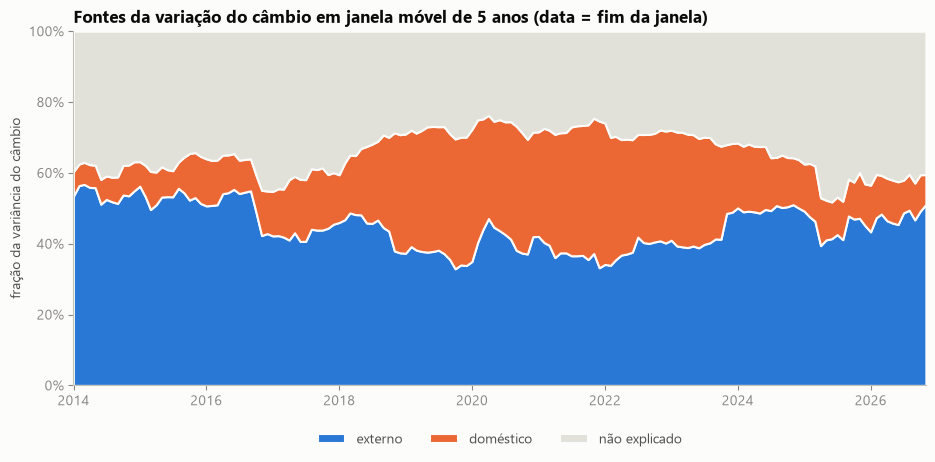

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.stackplot(reg60.index, reg60["externo"], reg60["doméstico"], reg60["não explicado"],
             colors=[AZUL, LARANJA, CINZA_CLARO], edgecolor=FUNDO, linewidth=1.5,
             labels=["externo", "doméstico", "não explicado"])
ax.set_ylim(0, 1)
ax.set_xlim(reg60.index[0], reg60.index[-1])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
eixo_anos(ax)
ax.grid(False)
ax.set_title("Fontes da variação do câmbio em janela móvel de 5 anos (data = fim da janela)")
ax.set_ylabel("fração da variância do câmbio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
salvar(fig, "4_composicao_no_tempo")

## Gráfico 5 — O risco-país decomposto

Variação acumulada do ln(CDS) desde dez/2008, separada em contágio global e parte brasileira.
A linha laranja termina em zero por construção (resíduos do MQO somam zero): leia os
**movimentos**, não o nível final.

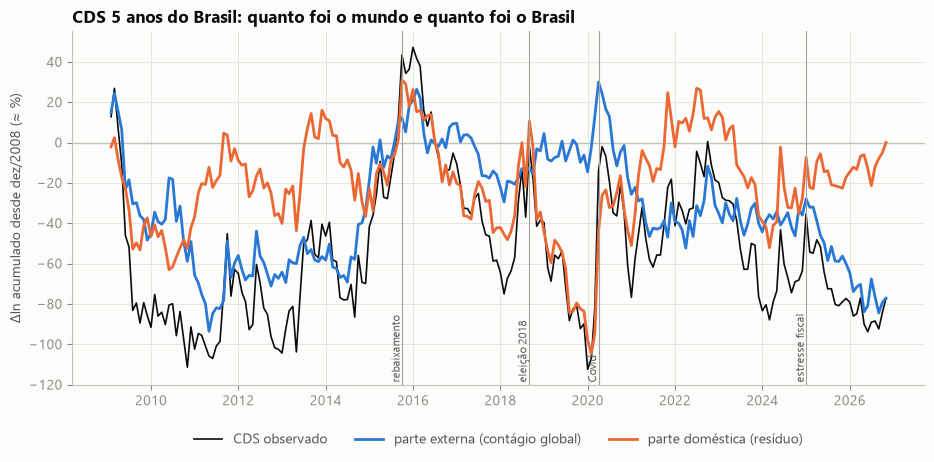

In [8]:
cds_dom = limpas["dl_cds_dom"]
cds_ext = variacoes["dl_cds"] - cds_dom

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axhline(0, color="#c3c2b7", lw=1)
ax.plot(variacoes["dl_cds"].cumsum(), color=TINTA, lw=1.2, label="CDS observado")
ax.plot(cds_ext.cumsum(), color=AZUL, lw=2, label="parte externa (contágio global)")
ax.plot(cds_dom.cumsum(), color=LARANJA, lw=2, label="parte doméstica (resíduo)")
for data, nome in episodios.items():
    ax.axvline(pd.Timestamp(data), color=CINZA_MEDIO, lw=0.8)
    ax.text(pd.Timestamp(data), ax.get_ylim()[0], f" {nome}", rotation=90, fontsize=8,
            color=TINTA_2, va="bottom", ha="right")
eixo_anos(ax)
ax.set_title("CDS 5 anos do Brasil: quanto foi o mundo e quanto foi o Brasil")
ax.set_ylabel("Δln acumulado desde dez/2008 (≈ %)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
salvar(fig, "5_cds_decomposto")

## Gráfico 6 — Versão para público não técnico (post)

Mesma linha principal do gráfico 3, sem jargão: uma série, a linha de 50% como referência
("quem pesa mais"), o mínimo marcado e anotações curtas para as fases.

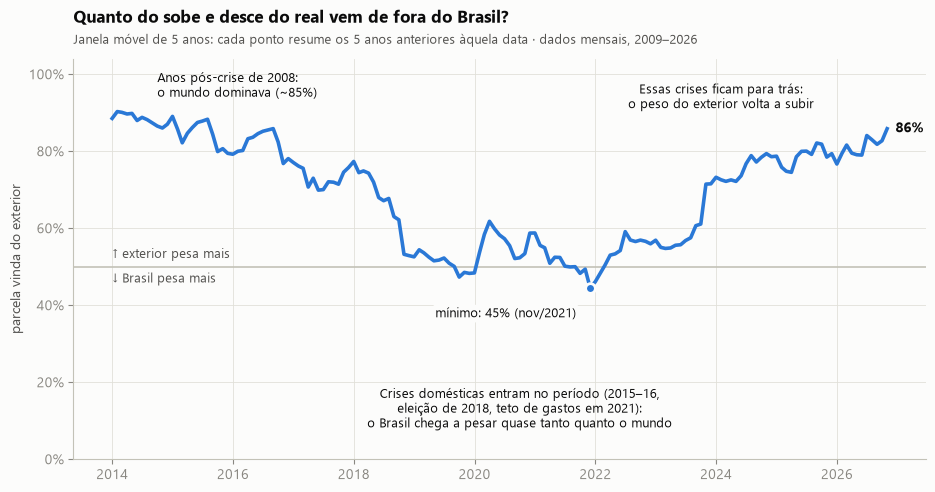

In [9]:
inicio = serie60.loc[:"2015-12"].mean()   # média da primeira fase

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.axhline(0.5, color="#c3c2b7", lw=1.2)
ax.text(serie60.index[0], 0.515, "↑ exterior pesa mais", fontsize=9, color=TINTA_2, va="bottom")
ax.text(serie60.index[0], 0.485, "↓ Brasil pesa mais", fontsize=9, color=TINTA_2, va="top")
ax.plot(serie60.index, serie60, color=AZUL, lw=2.6)
marcar_minimo(ax, serie60)

anotacoes = [
    ("2014-09-30", 0.97, "left", f"Anos pós-crise de 2008:\no mundo dominava (~{round(inicio * 20) * 5}%)"),
    ("2020-09-30", 0.13, "center", "Crises domésticas entram no período (2015–16,\neleição de 2018, teto de gastos em 2021):\no Brasil chega a pesar quase tanto quanto o mundo"),
    ("2024-01-31", 0.94, "center", "Essas crises ficam para trás:\no peso do exterior volta a subir"),
]
for data, y, alinhamento, texto in anotacoes:
    ax.text(pd.Timestamp(data), y, texto, fontsize=9.5, color=TINTA, ha=alinhamento, va="center")

ax.annotate(f"{serie60.iloc[-1]:.0%}", (serie60.index[-1], serie60.iloc[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=10, color=TINTA, fontweight="bold")

ax.set_ylim(0, 1.04)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
eixo_anos(ax)
ax.set_ylabel("parcela vinda do exterior")
ax.set_title("Quanto do sobe e desce do real vem de fora do Brasil?", pad=26)
ax.text(0, 1.03, "Janela móvel de 5 anos: cada ponto resume os 5 anos anteriores àquela data · dados mensais, 2009–2026",
        transform=ax.transAxes, fontsize=9, color=TINTA_2, va="bottom")
salvar(fig, "6_post_peso_exterior")

## Painel B — peso externo por fase (janelas de 60 meses, pela data de fim)

In [10]:
fases = {
    "1. dez/2013–dez/2015 (pós-2008, liquidez global)": ("2013-12", "2015-12"),
    "2. jan/2016–jul/2018 (crise doméstica entrando)":  ("2016-01", "2018-07"),
    "3. ago/2018–ago/2023 (domínio doméstico)":         ("2018-08", "2023-08"),
    "4. set/2023–out/2026 (crises de 2015–18 saem)":    ("2023-09", "2026-10"),
}
painel_b = pd.DataFrame({
    nome: {
        "externo": reg60.loc[ini:fim, "externo"].mean(),
        "doméstico": reg60.loc[ini:fim, "doméstico"].mean(),
        "não explicado": reg60.loc[ini:fim, "não explicado"].mean(),
        "externo / explicado": reg60.loc[ini:fim, "externo / explicado"].mean(),
        "nº de janelas": len(reg60.loc[ini:fim]),
    }
    for nome, (ini, fim) in fases.items()
}).T
painel_b.round(3)

,externo,doméstico,não explicado,externo / explicado,nº de janelas
"1. dez/2013–dez/2015 (pós-2008, liquidez global)",0.534,0.086,0.380,0.862,25.0
2. jan/2016–jul/2018 (crise doméstica entrando),0.469,0.147,0.384,0.761,31.0
3. ago/2018–ago/2023 (domínio doméstico),0.387,0.331,0.281,0.539,61.0
4. set/2023–out/2026 (crises de 2015–18 saem),0.472,0.139,0.389,0.775,38.0


## Painel C — decisões metodológicas

In [11]:
painel_c = pd.DataFrame([
    ("Variável dependente", "PTAX de venda (SGS 1), 100·Δln, mensal (último dia útil)"),
    ("Externas", "Treasury 10a (DGS10, Δ), VIX (VIXCLS, 100·Δln), dólar vs. economias avançadas (DTWEXAFEGS, 100·Δln), commodities (Bloomberg Commodity Index, 100·Δln)"),
    ("Domésticas", "Meta Selic (SGS 432, Δ), CDS 5a Investing.com (100·Δln), Focus resultado primário em horizonte fixo de 12m (Δ)"),
    ("Amostra", "jan/2009–out/2026 (214 meses); início definido pelo CDS sem preço velho"),
    ("Estacionariedade", "ADF e KPSS: todas as variações estacionárias"),
    ("Regressão", "MQO padronizado, erros-padrão HAC (Newey-West, 4 defasagens); dummy abr/2020 testada e descartada"),
    ("Limpeza", "Domésticas regredidas nas 4 externas; resíduo = componente doméstico (hipótese: economia pequena e aberta)"),
    ("Janelas móveis", "Regressão limpa em 60 meses (principal) e 84 meses (robustez); data = fim da janela"),
    ("Validação", "VAR com FEVD (pasta extra_var/) confirma 63% externo no explicado e as mesmas fases"),
    ("Limitações", "Exclui a crise de 2008; China e fluxo de capital fora do modelo; índice de commodities via download manual; sem intervalos de confiança nas janelas"),
], columns=["Item", "Escolha"]).set_index("Item")
painel_c

,Escolha
Item,
Variável dependente,"PTAX de venda (SGS 1), 100·Δln, mensal (último..."
Externas,"Treasury 10a (DGS10, Δ), VIX (VIXCLS, 100·Δln)..."
Domésticas,"Meta Selic (SGS 432, Δ), CDS 5a Investing.com ..."
Amostra,jan/2009–out/2026 (214 meses); início definido...
Estacionariedade,ADF e KPSS: todas as variações estacionárias
Regressão,"MQO padronizado, erros-padrão HAC (Newey-West,..."
Limpeza,Domésticas regredidas nas 4 externas; resíduo ...
Janelas móveis,Regressão limpa em 60 meses (principal) e 84 m...
Validação,VAR com FEVD (pasta extra_var/) confirma 63% e...


In [12]:
with pd.ExcelWriter(RES / "resumo.xlsx") as excel:
    painel_a.round(3).to_excel(excel, sheet_name="A - amostra completa")
    painel_b.round(3).to_excel(excel, sheet_name="B - fases")
    painel_c.to_excel(excel, sheet_name="C - decisões")

print("Figuras:", sorted(p.name for p in FIG.glob("*.png")))

Figuras: ['1_comparacao_metodos.png', '2_efeito_por_variavel.png', '3_peso_externo_no_tempo.png', '4_composicao_no_tempo.png', '5_cds_decomposto.png', '6_post_peso_exterior.png']
